# Exploração de operações morfolêgicas

Este notebook explora operações morfolêgicas **depois da limiarização**: abertura e fechamento. O objetivo ? observar o que elas fazem a uma máscara binária, não escolher automaticamente uma máscara definitiva. O limiar 100 ? mantido como valor experimental do notebook anterior, não como regra de segmentação.

## Ideia matemática

As operações usam um elemento estruturante, que define a forma e a vizinhança em que a máscara será examinada:

- **OpenCV** (`cv2.morphologyEx`): executa abertura e fechamento no corte 2D.
- **SciPy** (`scipy.ndimage`): mantém as operações 3D no volume.
- **Erosão:** mantém um voxel branco apenas quando a vizinhança do elemento estruturante cabe completamente na região branca.
- **Dilatação:** torna branco um voxel quando a vizinhança toca uma região branca.
- **Abertura = erosão seguida de dilatação:** pode remover pequenas regiões brancas isoladas ou saliências finas.
- **Fechamento = dilatação seguida de erosão:** pode preencher pequenos buracos escuros e aproximar bordas brancas.

Essas operações podem remover detalhes úteis, unir estruturas que deveriam continuar separadas ou preencher espaços que deveriam permanecer vazios. A contagem de voxels alterados descreve a mudança, mas não comprova qualidade anatômica.

O elemento estruturante ? construído usando o espaçamento físico `(z, y, x)` obtido dos metadados DICOM e um raio demonstrativo de 2 mm. Sua forma em voxels depende desse espaçamento.

As máscaras e os resultados ficam somente em memória. Este notebook não altera os arquivos DICOM originais, não apaga componentes, não salva um resultado processado nem reconstrói uma superfície.

## 1. Carregar a imagem e montar uma máscara de demonstração

Usamos o limiar experimental 100 apenas para comparar as operações com um ponto de partida repetível. Para cada voxel, `volume > threshold` produz `True` (branco) quando a intensidade passa do limiar e `False` (preto) caso contrário. OpenCV já faz parte do ambiente por causa do experimento com limiarização; o SciPy fornece as operações morfológicas.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import cv2
import sys
from scipy import ndimage

current_dir = Path.cwd().resolve()
search_dirs = [current_dir, *current_dir.parents]
search_dirs.extend(parent / "reconstrucao-cranio" for parent in search_dirs.copy())
project_root = next(
    (folder for folder in search_dirs if (folder / "data" / "skull").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Não encontrei data/skull. "
        f"Diretório de trabalho atual do Jupyter: {current_dir}."
    )

src_path = str(project_root / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)
from leitura import ler_dicom_volume

data_dir = project_root / "data" / "skull" / "0051" / "0051"
volume, voxel_spacing_zyx, image_files = ler_dicom_volume(data_dir)
if volume.ndim != 3 or volume.shape[0] != len(image_files):
    raise ValueError(
        f"Volume DICOM inesperado: dimensões {volume.shape}, tipo {volume.dtype}."
    )

threshold = 100
_, mask_flat = cv2.threshold(
    volume.reshape(-1, 1), float(threshold), 1, cv2.THRESH_BINARY
)
mask = mask_flat.reshape(volume.shape).astype(bool)
slice_index = volume.shape[0] // 2
print(f"Volume MRI: {volume.shape}, tipo {volume.dtype}")
print(f"Espaçamento DICOM (z, y, x), em mm: {voxel_spacing_zyx}")
print(f"Limiar de demonstração: {threshold} (exploratério, não validado)")
print(f"Fração da máscara inicial: {mask.mean():.2%}")

Volume MRI: (108, 512, 512), tipo uint16
Espaçamento DICOM (z, y, x), em mm: (1.5, 0.4785156, 0.4785156)
Limiar de demonstração: 100 (exploratério, não validado)
Fração da máscara inicial: 41.93%


## 2. Construir o elemento estruturante respeitando o espaçamento

O voxel central está na origem `(z, y, x) = (0, 0, 0)`. Incluímos um deslocamento quando sua distância física até o centro ? menor ou igual ao raio. A distância ? calculada como `sqrt((z ? s_z)? + (y ? s_y)? + (x ? s_x)?)`, onde `s` ? o espaçamento físico em cada eixo, lido dos metadados DICOM. A fatia central desse elipsoide ? usada para comparar uma operação em um único corte.

In [2]:
radius_mm = 2.0
axis_radii = tuple(
    int(np.ceil(radius_mm / spacing)) for spacing in voxel_spacing_zyx
)
z, y, x = np.ogrid[
    -axis_radii[0] : axis_radii[0] + 1,
    -axis_radii[1] : axis_radii[1] + 1,
    -axis_radii[2] : axis_radii[2] + 1,
]
physical_distance_squared = (
    (z * voxel_spacing_zyx[0]) ** 2
    + (y * voxel_spacing_zyx[1]) ** 2
    + (x * voxel_spacing_zyx[2]) ** 2
)
footprint_3d = physical_distance_squared <= radius_mm**2
footprint_2d = footprint_3d[axis_radii[0]]

print(f"Espaçamento DICOM (z, y, x), em mm: {voxel_spacing_zyx}")
print(f"Raio físico de demonstração: {radius_mm} mm")
print(f"Elemento estruturante 3D: {footprint_3d.shape}; voxels incluídos: {footprint_3d.sum()}")
print(f"Disco central 2D: {footprint_2d.shape}; pixels incluídos: {footprint_2d.sum()}")

expected_shape = tuple(2 * radius + 1 for radius in axis_radii)
if footprint_3d.shape != expected_shape:
    raise ValueError(f"Elemento estruturante 3D inesperado: {footprint_3d.shape}.")

Espaçamento DICOM (z, y, x), em mm: (1.5, 0.4785156, 0.4785156)
Raio físico de demonstração: 2.0 mm
Elemento estruturante 3D: (5, 11, 11); voxels incluídos: 99
Disco central 2D: (11, 11); pixels incluídos: 57


## 3. Comparar operações 2D e 3D no corte central

As versões 2D enxergam apenas o corte central. As versões 3D levam em conta também os cortes vizinhos. A fatia central do elemento estruturante 3D ? usada na comparação 2D.

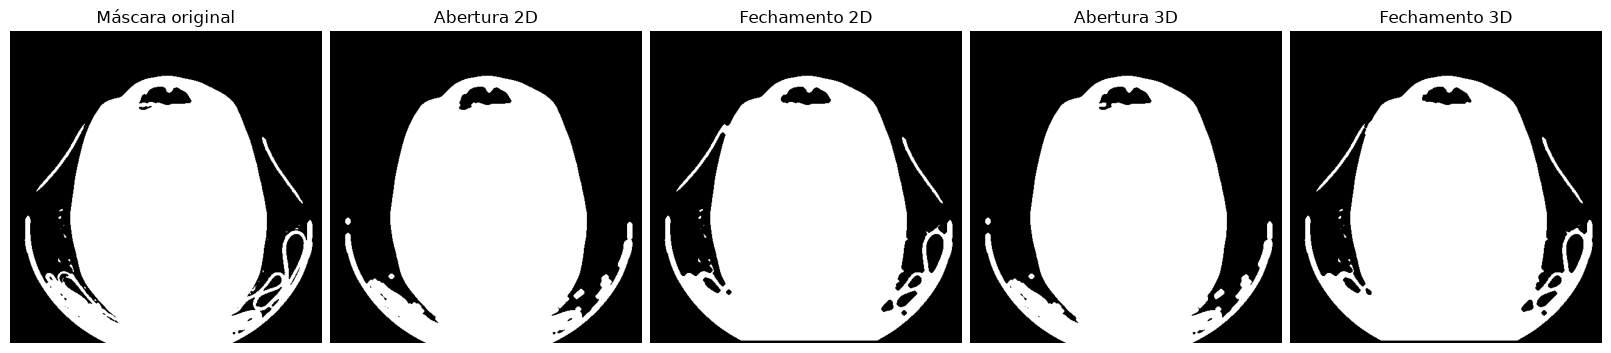

Abertura 2D: 3,868 pixels alterados no corte central
Fechamento 2D: 2,596 pixels alterados no corte central
Abertura 3D: 3,816 pixels alterados no corte central
Fechamento 3D: 2,589 pixels alterados no corte central


In [3]:
mask_central = mask[slice_index]
mask_central_u8 = mask_central.astype(np.uint8) * 255
kernel_2d = footprint_2d.astype(np.uint8)
opening_2d = cv2.morphologyEx(
    mask_central_u8, cv2.MORPH_OPEN, kernel_2d,
    borderType=cv2.BORDER_CONSTANT, borderValue=0
) > 0
closing_2d = cv2.morphologyEx(
    mask_central_u8, cv2.MORPH_CLOSE, kernel_2d,
    borderType=cv2.BORDER_CONSTANT, borderValue=0
) > 0
opening_3d = ndimage.binary_opening(mask, structure=footprint_3d)
closing_3d = ndimage.binary_closing(mask, structure=footprint_3d)

central_results = [
    (mask_central, "Máscara original"),
    (opening_2d, "Abertura 2D"),
    (closing_2d, "Fechamento 2D"),
    (opening_3d[slice_index], "Abertura 3D"),
    (closing_3d[slice_index], "Fechamento 3D"),
]
fig, axes = plt.subplots(1, len(central_results), figsize=(16, 4), layout="constrained")
for ax, (result, title) in zip(axes, central_results):
    ax.imshow(result, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.show()

for name, result in (
    ("Abertura 2D", opening_2d),
    ("Fechamento 2D", closing_2d),
    ("Abertura 3D", opening_3d[slice_index]),
    ("Fechamento 3D", closing_3d[slice_index]),
):
    changed = np.count_nonzero(result != mask_central)
    print(f"{name}: {changed:,} pixels alterados no corte central")

## 4. Inspecionar o resultado ao longo dos cortes

Mostramos o primeiro, o central e o último corte da máscara original, da abertura 3D e do fechamento 3D. As operações 3D já foram calculadas considerando a sequência inteira. As contagens de voxels ajudam a quantificar a mudança, mas não determinam, por si sós, qual resultado é melhor.

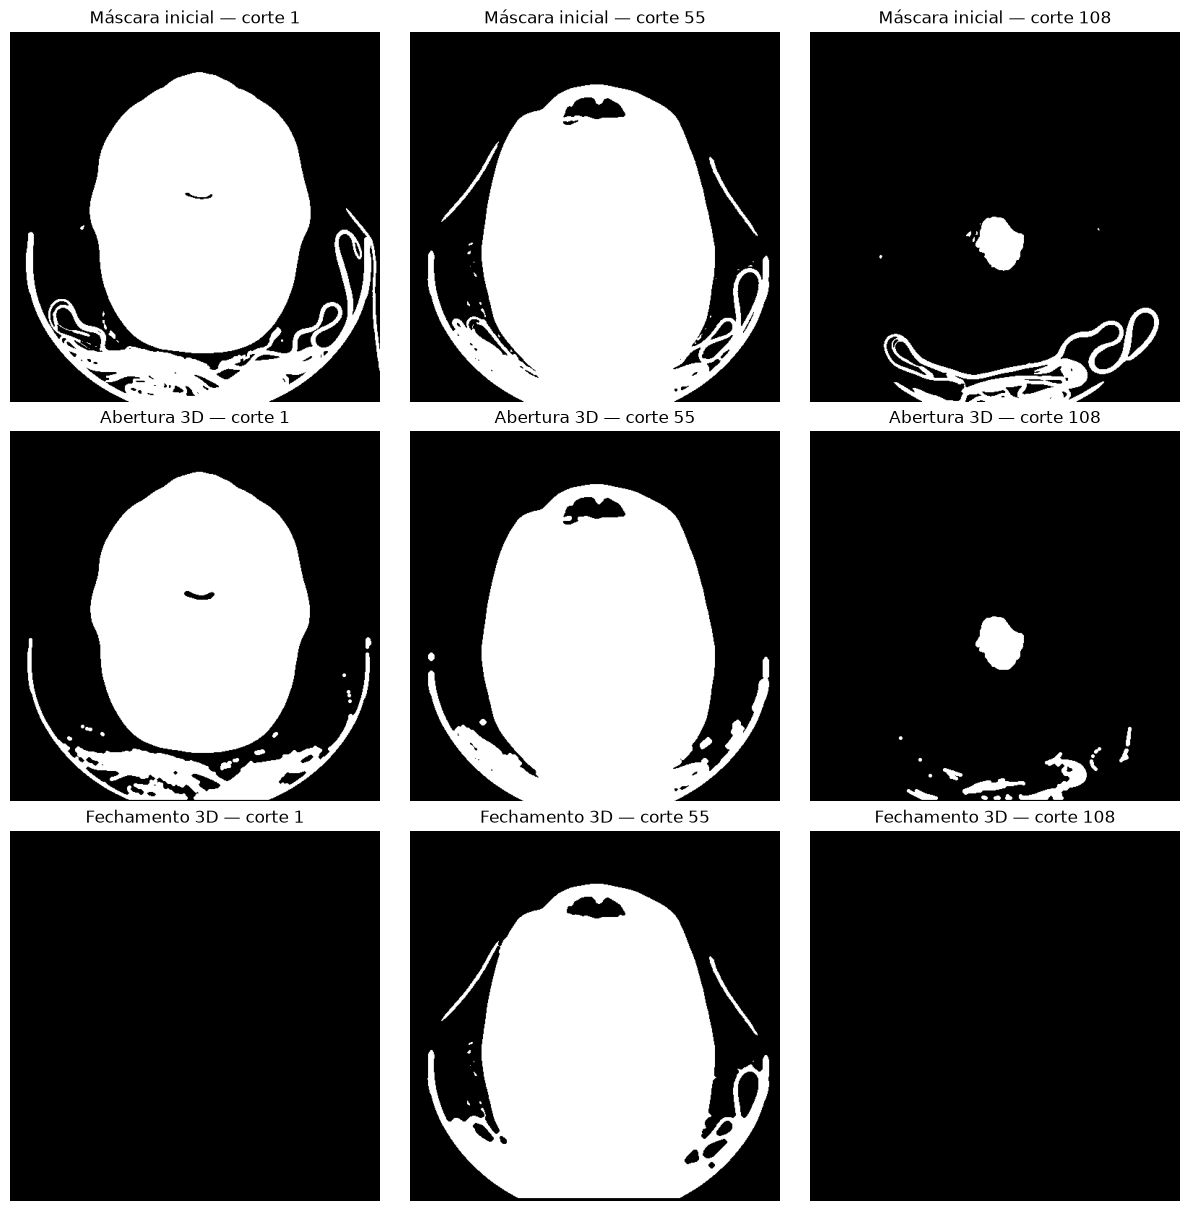

Máscara inicial: 11,870,410 voxels brancos (41.93%); 0 voxels diferentes da máscara inicial
Abertura 3D: 11,426,215 voxels brancos (40.36%); 444,195 voxels diferentes da máscara inicial
Fechamento 3D: 11,913,430 voxels brancos (42.08%); 494,888 voxels diferentes da máscara inicial


In [4]:
results_3d = [
    (mask, "Máscara inicial"),
    (opening_3d, "Abertura 3D"),
    (closing_3d, "Fechamento 3D"),
]
slice_indices = (0, slice_index, len(volume) - 1)
fig, axes = plt.subplots(3, 3, figsize=(12, 12), layout="constrained")
for row, (result, operation_name) in enumerate(results_3d):
    for column, index in enumerate(slice_indices):
        axes[row, column].imshow(result[index], cmap="gray", vmin=0, vmax=1)
        axes[row, column].set_title(f"{operation_name} — corte {index + 1}")
        axes[row, column].axis("off")
plt.show()

for result, name in results_3d:
    changed = np.count_nonzero(result != mask)
    print(
        f"{name}: {np.count_nonzero(result):,} voxels brancos "
        f"({result.mean():.2%}); {changed:,} voxels diferentes da máscara inicial"
    )

if not (
    opening_3d.shape == mask.shape
    and closing_3d.shape == mask.shape
    and opening_3d.dtype == np.bool_
    and closing_3d.dtype == np.bool_
):
    raise ValueError("Os resultados morfológicos não preservaram formato e tipo da máscara.")

## Interpretar antes de avançar

Verifique se a abertura removeu estruturas pequenas ou conexões finas que talvez fossem relevantes. Observe se o fechamento preencheu buracos úteis ou uniu regiões independentes. Compare também os cortes 2D com os resultados 3D: a versão 3D pode usar informação dos cortes vizinhos para mudar a máscara do corte atual.

Nenhuma operação morfolêgica foi escolhida como definitiva e nenhuma máscara foi salva. A próxima decisão depende da inspeção visual; os resultados permanecem exploratérios.